In [44]:
#Car_Price_Prediction

In [ ]:
#description
"""
The Car Price Prediction project aims to build machine learning models that can accurately estimate the
market price of a car based on its features. The dataset includes 205 cars with 26 attributes such as 
engine size, horsepower, fuel type, body style, dimensions, mileage, and car brand.
The analysis includes:
Data loading and understanding
Missing value checks and cleaning
Summary statistics and distribution analysis
Visualization of key variables
Correlation, skewness, and kurtosis analysis
Label encoding of categorical features
Training regression models including Linear Regression, Decision Tree, and Random Forest
Model evaluation using MAE and R² Score
Feature importance ranking
The goal is to determine which factors most strongly influence car prices and which ML model 
performs best for this prediction task.
"""

In [43]:
#Importing the required Python libraries and machine learning modules."
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import math
from rich import print
import missingno

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams["figure.figsize"] = (10, 8)

In [ ]:
#Data loading and Basic Data Exploration

In [5]:
cp=pd.read_csv("CarPrice_Assignment.csv")

In [7]:
cp.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [8]:
cp.tail()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
200,201,-1,volvo 145e (sw),gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845.0
201,202,-1,volvo 144ea,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045.0
202,203,-1,volvo 244dl,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485.0
203,204,-1,volvo 246,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470.0
204,205,-1,volvo 264gl,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625.0


In [9]:
cp.sample()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
46,47,2,isuzu D-Max,gas,std,two,hatchback,rwd,front,96.0,...,119,spfi,3.43,3.23,9.2,90,5000,24,29,11048.0


In [11]:
cp.shape

(205, 26)

In [12]:
cp.columns

Index(['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration',
       'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase',
       'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype',
       'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke',
       'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg',
       'price'],
      dtype='object')

In [13]:
cp.size

5330

In [14]:
cp.nunique()

car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength            75
carwidth             44
carheight            49
curbweight          171
enginetype            7
cylindernumber        7
enginesize           44
fuelsystem            8
boreratio            38
stroke               37
compressionratio     32
horsepower           59
peakrpm              23
citympg              29
highwaympg           30
price               189
dtype: int64

In [15]:
cp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

In [16]:
cp.describe()

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


In [17]:
cp.describe(include='all')

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205,205,205,205,205,205,205,205.000000,...,205.000000,205,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
unique,NaN,NaN,147,2,2,2,5,3,2,NaN,...,NaN,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,peugeot 504,gas,std,four,sedan,fwd,front,NaN,...,NaN,mpfi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,6,185,168,115,96,120,202,NaN,...,NaN,94,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,103.000000,0.834146,NaN,NaN,NaN,NaN,NaN,NaN,NaN,98.756585,...,126.907317,NaN,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.021776,...,41.642693,NaN,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,86.600000,...,61.000000,NaN,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,94.500000,...,97.000000,NaN,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,97.000000,...,120.000000,NaN,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,102.400000,...,141.000000,NaN,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000


In [19]:
cp.isna().sum()

car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

In [20]:
cp.dtypes

car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke              float64
compressionratio    float64
horsepower            int64
peakrpm               int64
citympg               int64
highwaympg            int64
price               float64
dtype: object

In [21]:
cp.isnull().sum()

car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

In [22]:
cp['car_ID'].value_counts()

car_ID
1      1
2      1
3      1
4      1
5      1
      ..
201    1
202    1
203    1
204    1
205    1
Name: count, Length: 205, dtype: int64

In [23]:
cp.head().T

,0,1,2,3,4
car_ID,1,2,3,4,5
symboling,3,3,1,2,2
CarName,alfa-romero giulia,alfa-romero stelvio,alfa-romero Quadrifoglio,audi 100 ls,audi 100ls
fueltype,gas,gas,gas,gas,gas
aspiration,std,std,std,std,std
doornumber,two,two,two,four,four
carbody,convertible,convertible,hatchback,sedan,sedan
drivewheel,rwd,rwd,rwd,fwd,4wd
enginelocation,front,front,front,front,front
wheelbase,88.6,88.6,94.5,99.8,99.4


In [28]:
print(cp['price'].describe())

count      205.000000
mean     13276.710571
std       7988.852332
min       5118.000000
25%       7788.000000
50%      10295.000000
75%      16503.000000
max      45400.000000
Name: price, dtype: float64

In [30]:
print(cp.groupby(['CarName','price']).size().head())

CarName                   price  
Nissan versa              5499.0     1
alfa-romero Quadrifoglio  16500.0    1
alfa-romero giulia        13495.0    1
alfa-romero stelvio       16500.0    1
audi 100 ls               13950.0    1
dtype: int64

In [38]:
print(cp[cp['price']>20000].head())

car_ID  symboling    CarName fueltype aspiration doornumber carbody  \
8        9          1  audi 4000      gas      turbo       four   sedan   
12      13          0     bmw x1      gas        std        two   sedan   
13      14          0     bmw x3      gas        std       four   sedan   
14      15          1     bmw z4      gas        std       four   sedan   
15      16          0     bmw x4      gas        std       four   sedan   

   drivewheel enginelocation  wheelbase  ...  enginesize  fuelsystem  \
8         fwd          front      105.8  ...         131        mpfi   
12        rwd          front      101.2  ...         164        mpfi   
13        rwd          front      101.2  ...         164        mpfi   
14        rwd          front      103.5  ...         164        mpfi   
15        rwd          front      103.5  ...         209        mpfi   

    boreratio  stroke compressionratio horsepower  peakrpm citympg  \
8        3.13    3.40              8.3        140     5500      17   
12       3.31    3.19              9.0        121     4250      21   
13       3.31    3.19              9.0        121     4250      21   
14       3.31    3.19              9.0        121     4250      20   
15       3.62    3.39              8.0        182     5400      16   

    highwaympg    price  
8           20  23875.0  
12          28  20970.0  
13          28  21105.0  
14          25  24565.0  
15          22  30760.0  

[5 rows x 26 columns]

In [39]:
cp.ndim

2

In [40]:
cp.index

RangeIndex(start=0, stop=205, step=1)

In [41]:
cp.notnull()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
1,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
2,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
3,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
4,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
201,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
202,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
203,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True


In [42]:
cp.max()

car_ID                    205
symboling                   3
CarName             vw rabbit
fueltype                  gas
aspiration              turbo
doornumber                two
carbody                 wagon
drivewheel                rwd
enginelocation           rear
wheelbase               120.9
carlength               208.1
carwidth                 72.3
carheight                59.8
curbweight               4066
enginetype              rotor
cylindernumber            two
enginesize                326
fuelsystem               spfi
boreratio                3.94
stroke                   4.17
compressionratio         23.0
horsepower                288
peakrpm                  6600
citympg                    49
highwaympg                 54
price                 45400.0
dtype: object

In [43]:
cp.duplicated().sum()

np.int64(0)

In [46]:
cp.drop(['stroke'], axis=1, inplace=True)

In [47]:
cp.columns

Index(['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration',
       'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase',
       'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype',
       'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio',
       'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg',
       'price'],
      dtype='object')

In [ ]:
#“Exploratory Data Analysis (EDA) – Visualizations”

<bound method IndexOpsMixin.value_counts of 0      dohc
1      dohc
2      ohcv
3       ohc
4       ohc
       ... 
200     ohc
201     ohc
202    ohcv
203     ohc
204     ohc
Name: enginetype, Length: 205, dtype: object>

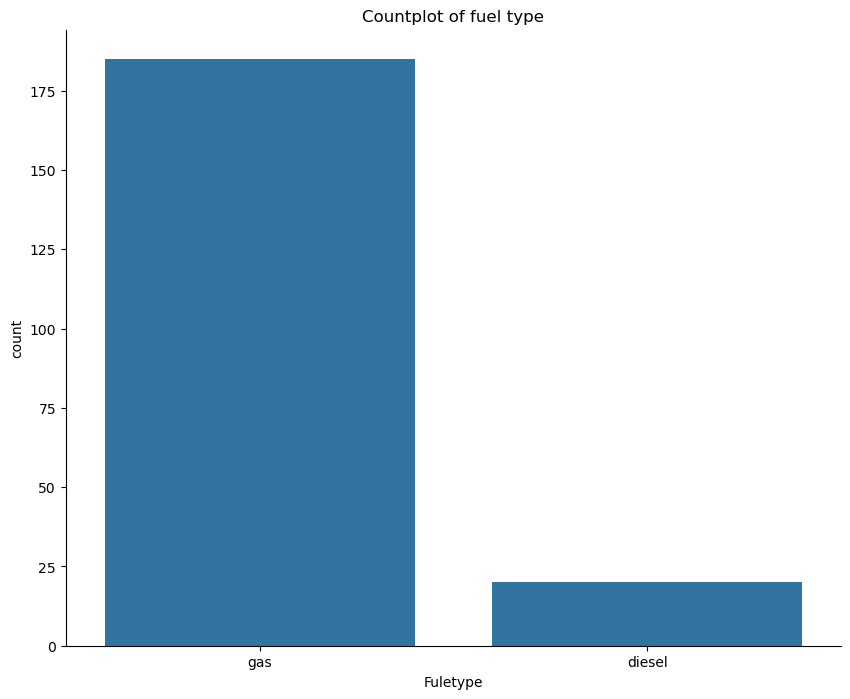

In [73]:
#countplot
sns.countplot(x=cp['fueltype'],data=cp)
plt.xlabel("Fuletype")
plt.ylabel("count")
plt.title("Countplot of fuel type")
sns.despine()
print(cp.enginetype.value_counts)
plt.show()

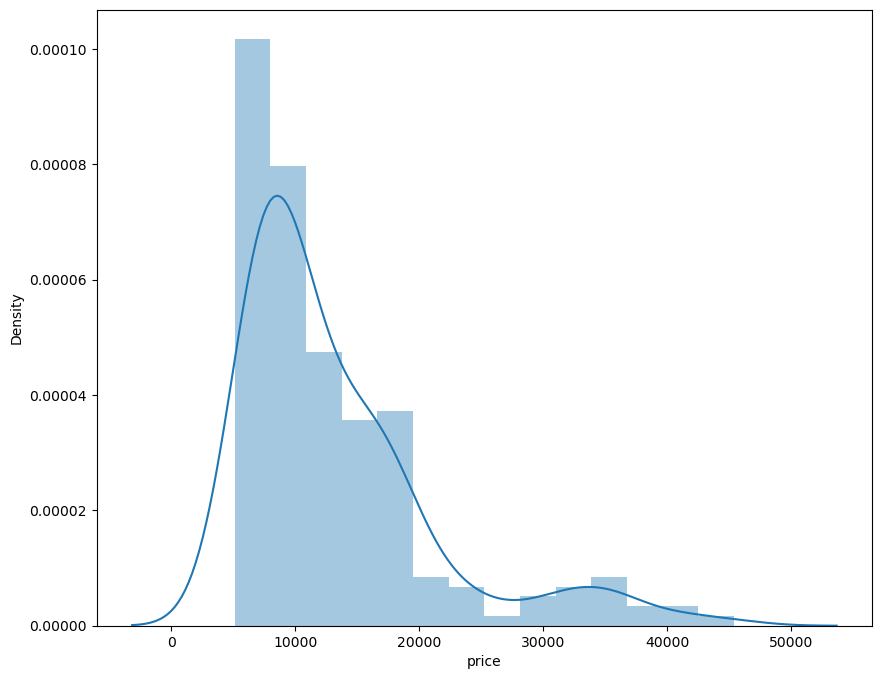

In [75]:
#distplot
sns.distplot(cp['price'], hist=True, kde=True)
plt.show()

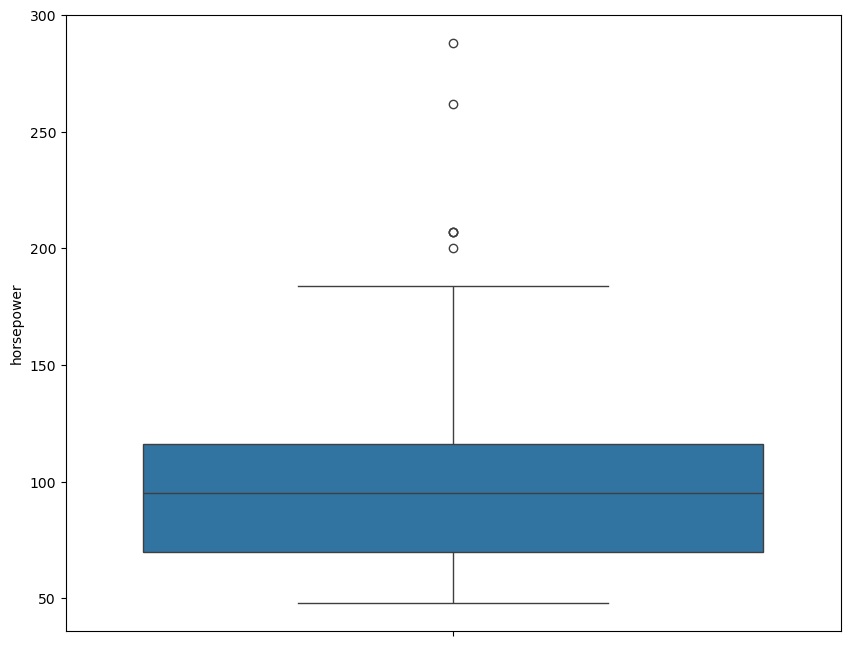

In [72]:
#boxplot
sns.boxplot(cp['horsepower'])
plt.show()

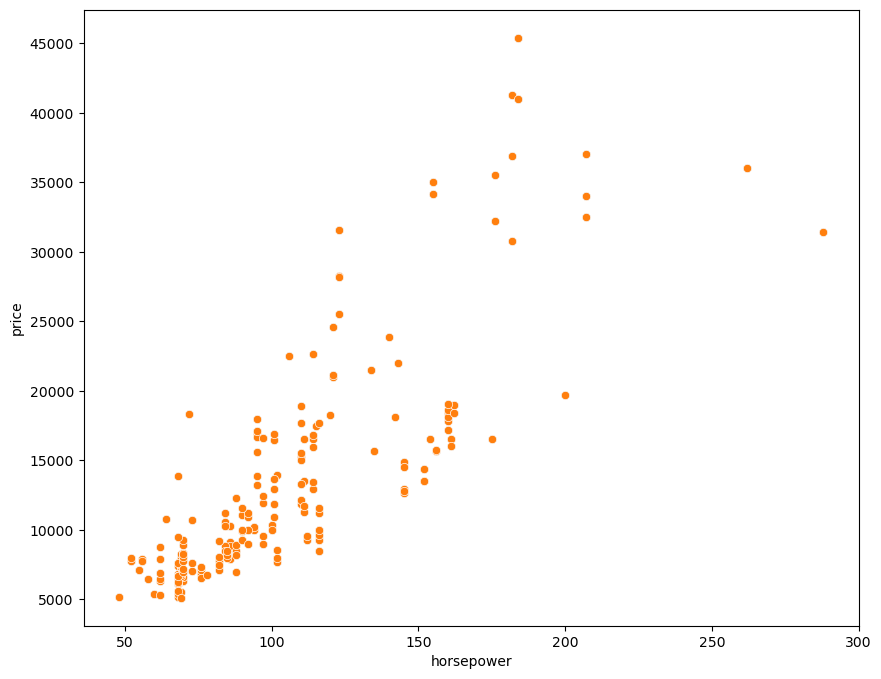

In [77]:
#scatterplot
sns.scatterplot(x='horsepower', y='price', data=cp)
plt.show()

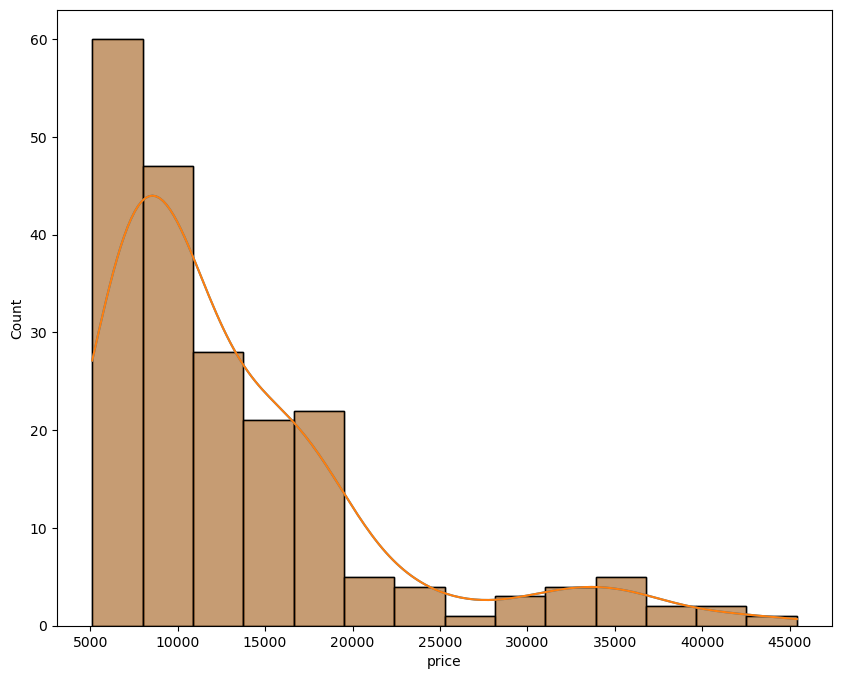

In [79]:
#histplot
sns.histplot(cp['price'], kde=True)
plt.show()

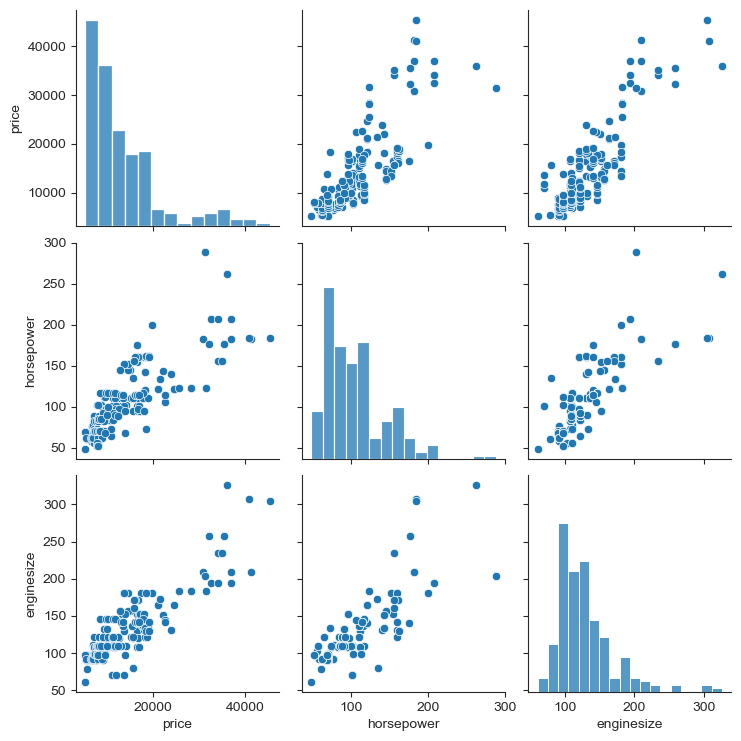

In [82]:
#pairplot
sns.set_style('ticks')
sns.pairplot(cp[['price', 'horsepower', 'enginesize']])
plt.show()

In [ ]:
#Correlion,Skewness & Kurtosis Analysis

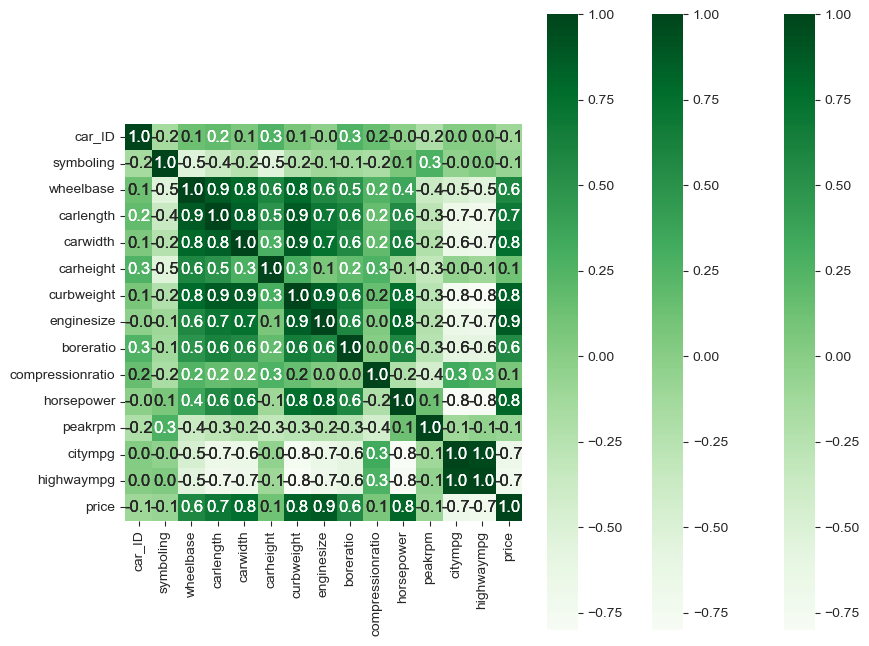

In [88]:
corr=cp.select_dtypes(include=['number']).corr()
sns.heatmap(corr,fmt='.1f',cbar=True,square=True,annot=True,annot_kws={'size':12},cmap='Greens')
plt.show()

In [90]:
skew=cp.select_dtypes(include=['number']).skew()
print(skew)

car_ID              0.000000
symboling           0.211072
wheelbase           1.050214
carlength           0.155954
carwidth            0.904003
carheight           0.063123
curbweight          0.681398
enginesize          1.947655
boreratio           0.020156
compressionratio    2.610862
horsepower          1.405310
peakrpm             0.075159
citympg             0.663704
highwaympg          0.539997
price               1.777678
dtype: float64

In [65]:
kurt=cp.select_dtypes(include=['number']).kurt()
print(kurt)

car_ID                 -1.200000
symboling              -0.676271
CarName                -1.106053
wheelbase               1.017039
carlength              -0.082895
carwidth                0.702764
carheight              -0.443812
curbweight             -0.042854
enginesize              5.305682
boreratio              -0.785042
stroke                  2.174396
compressionratio        5.233054
horsepower              2.684006
peakrpm                 0.086756
citympg                 0.578648
highwaympg              0.440070
price                   3.051648
carbody_convertible    29.951496
carbody_hardtop        21.208495
carbody_hatchback      -1.561613
carbody_sedan          -2.003250
carbody_wagon           3.451628
fueltype_diesel         5.520976
fueltype_gas            5.520976
dtype: float64

In [66]:
cp.head()

,car_ID,symboling,CarName,aspiration,doornumber,drivewheel,enginelocation,wheelbase,carlength,carwidth,...,citympg,highwaympg,price,carbody_convertible,carbody_hardtop,carbody_hatchback,carbody_sedan,carbody_wagon,fueltype_diesel,fueltype_gas
0,1,3,2,std,two,rwd,front,88.6,168.8,64.1,...,21,27,13495.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2,3,3,std,two,rwd,front,88.6,168.8,64.1,...,21,27,16500.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,3,1,1,std,two,rwd,front,94.5,171.2,65.5,...,19,26,16500.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,4,2,4,std,four,fwd,front,99.8,176.6,66.2,...,24,30,13950.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
4,5,2,5,std,four,4wd,front,99.4,176.6,66.4,...,18,22,17450.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


In [ ]:
#label encoding and one-hot encoding

In [19]:
le = LabelEncoder()
fuel_type = le.fit_transform(cp['fueltype'])
fuel_type[:5]

array([1, 1, 1, 1, 1])

In [ ]:
one = OneHotEncoder()
embarked_encoded = cp['fueltype']
en_b = one.fit_transform(embarked_encoded.values.reshape(-1,1))
embarked_cp = pd.DataFrame(en_b, columns=one.get_feature_names_out(['fueltype']))
embarked_cp.head()

In [10]:
le = LabelEncoder()
cp['aspiration'] = le.fit_transform(cp['aspiration'])

In [11]:
le = LabelEncoder()
cp['doornumber'] = le.fit_transform(cp['doornumber'])

In [12]:
le = LabelEncoder()
cp['drivewheel'] = le.fit_transform(cp['drivewheel'])

In [13]:
le = LabelEncoder()
cp['enginelocation'] = le.fit_transform(cp['enginelocation'])

In [14]:
le = LabelEncoder()
cp['enginetype'] = le.fit_transform(cp['enginetype'])

In [15]:
le = LabelEncoder()
cp['cylindernumber'] = le.fit_transform(cp['cylindernumber'])

In [16]:
le = LabelEncoder()
cp['fuelsystem'] = le.fit_transform(cp['fuelsystem'])

In [24]:
le = LabelEncoder()
cp['carbody'] = le.fit_transform(cp['carbody'])

In [26]:
le = LabelEncoder()
cp['CarName'] = le.fit_transform(cp['CarName'])

In [27]:
le = LabelEncoder()
cp['fueltype'] = le.fit_transform(cp['fueltype'])

In [28]:
cp.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,2,1,0,1,0,2,0,88.6,...,130,5,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,3,1,0,1,0,2,0,88.6,...,130,5,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,1,1,0,1,2,2,0,94.5,...,152,5,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,4,1,0,0,3,1,0,99.8,...,109,5,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,5,1,0,0,3,0,0,99.4,...,136,5,3.19,3.40,8.0,115,5500,18,22,17450.0


In [ ]:
#model training

In [37]:
X = cp.drop('price', axis=1)
y = cp['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
##Model Building and Evaluation

In [38]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [35]:
from sklearn.model_selection import cross_val_score

X = cp.drop('price', axis=1)
y = cp['price']

model = LinearRegression()
scores = cross_val_score(model, X, y, cv=5, scoring='r2')

print("Cross-validation R² scores:", scores)
print("Mean R²:", scores.mean())


Cross-validation R² scores: [ 0.68574565  0.88051734 -0.07519798  0.46710602  0.4161461 ]

Mean R²: 0.4748634259224464

In [33]:
model = DecisionTreeRegressor(random_state=42)
model.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

In [40]:
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [39]:
y_pred=model.predict(X_test)

In [41]:
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R² Score:", r2_score(y_test, y_pred))

MAE: 2087.3062123228165

R² Score: 0.8441158536668157

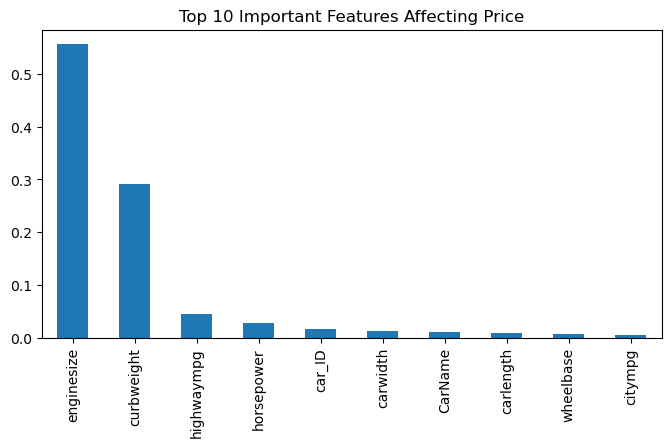

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

importances = pd.Series(model.feature_importances_, index=X.columns)
importances.sort_values(ascending=False).head(10).plot(kind='bar', figsize=(8,4))
plt.title("Top 10 Important Features Affecting Price")
plt.show()


In [ ]:
#Conclusion
"""
The Car Price Prediction analysis provides a complete machine learning workflow starting from data exploration to model evaluation.
The dataset was thoroughly examined with descriptive statistics, visualizations, correlation matrices, and distribution analysis. 
Key features such as engine size, curb weight, horsepower, and car dimensions showed strong positive relationships with price.
Among the models tested, the Random Forest Regressor delivered the best results with an R² Score of 0.84, indicating strong 
predictive ability. It also achieved the lowest MAE, making it the most accurate model in estimating car prices. 
Feature importance analysis showed that engine size, curb weight, horsepower, and highway mileage were the most influential
factors affecting price.
Overall, the project successfully demonstrated the effectiveness of machine learning techniques in predicting car prices 
and highlighted the key variables that contribute most to price variation. This model can be further improved with more data,
advanced feature engineering, or hyperparameter tuning.
"""